# 04. Four-Tier Ablation Benchmark & Architectural Trade-Off Visualization

### Experimental Design
In this notebook, we execute a controlled 4-tier ablation study across **10 diagnostic queries** (5 **Descriptive BI** metrics + 5 **Multi-Hop Causal** root-cause questions) using the exact same underlying LLM (`gemini-3.5-flash-lite`, `temperature=0.0`):
1. **Tier 1 (`Tier1_RawLogs`):** Stateless Text-to-SQL directly over 42.45M `bronze_events` rows.
2. **Tier 2 (`Tier2_SemanticLayer`):** Text-to-SQL over stateful, bot-filtered `silver_sessions`.
3. **Tier 3 (`Tier3_Ontology`):** Deterministic NetworkX graph traversal tools with zero domain prompt engineering.
4. **Tier 4 (`Tier4_Ontology_PromptEng`):** Tier 3 graph tools augmented with explicit **Domain Axioms**, **Dynamic TF-IDF Golden Query Retrieval**, and **Strict JSON Grounding**.


In [2]:
import sys
import importlib
import time
import pandas as pd

# Reload local src/ modules so Databricks picks up your latest edits immediately
sys.path.append("../src")
import schemas
import golden_queries
import agents

importlib.reload(schemas)
importlib.reload(golden_queries)
importlib.reload(agents)
from agents import ThreeTierBenchmarkAgents

# Ensure API key widget exists and read key safely from the left sidebar
dbutils.widgets.text("llm_api_key", "", "Paste API Key Here")
API_KEY = dbutils.widgets.get("llm_api_key")
assert API_KEY != "", "Please paste your Gemini API key into the 'Paste API Key Here' box on the left sidebar!"

# runner_client = ThreeTierBenchmarkAgents(
#     spark=spark,
#     api_key=API_KEY,
#     model="gemini-4-hydrogen",
#     base_url="https://googleapis.com",
# )

# GEMINI_BASE_URL = "https://" + "://googleapis.com" + "/v1beta/openai/"

# runner_client = ThreeTierBenchmarkAgents(
#     spark=spark,
#     api_key=API_KEY,
#     model="gemini-4-hydrogen",
#     base_url=GEMINI_BASE_URL,
# )

host = "generativelanguage" + "." + "googleapis" + "." + "com"
GEMINI_BASE_URL = f"https://{host}/v1beta/openai/"

runner_client = ThreeTierBenchmarkAgents(
    spark=spark,
    api_key=API_KEY,
    #model="gemini-4-hydrogen",
    #model="gemini-2.5-flash-lite",
    model="gemini-3.6-flash",
    base_url=GEMINI_BASE_URL,
)



# Helper functions to compute exact deterministic Ground Truth from Silver & Ontology tables
def get_scalar(sql_str: str) -> float:
    return float(spark.sql(sql_str).first()["val"])

def get_top_edge(src: str, rel: str):
    row = spark.sql(
        f"SELECT target_id, SUM(weight) AS w FROM workspace.default.ont_edges "
        f"WHERE source_id = '{src}' AND relation_type = '{rel}' "
        f"GROUP BY target_id ORDER BY w DESC LIMIT 1"
    ).first()
    _, entity_name = row["target_id"].split(":", 1)
    return entity_name, float(row["w"])


# Ground Truth for Descriptive BI queries (known brands, excluding bot traffic)
gt_elec_rev = get_scalar("SELECT ROUND(SUM(session_revenue), 2) AS val FROM workspace.default.silver_sessions WHERE is_bot_suspect = false AND primary_category = 'electronics' AND final_brand != 'unknown'")
gt_app_rev = get_scalar("SELECT ROUND(SUM(session_revenue), 2) AS val FROM workspace.default.silver_sessions WHERE is_bot_suspect = false AND primary_category = 'appliances' AND final_brand != 'unknown'")
gt_comp_rev = get_scalar("SELECT ROUND(SUM(session_revenue), 2) AS val FROM workspace.default.silver_sessions WHERE is_bot_suspect = false AND primary_category = 'computers' AND final_brand != 'unknown'")
gt_elec_direct = get_scalar("SELECT ROUND(SUM(CASE WHEN funnel_outcome = 'direct_purchase_no_cart' THEN 1 ELSE 0 END) * 100.0 / SUM(CASE WHEN purchase_count > 0 THEN 1 ELSE 0 END), 2) AS val FROM workspace.default.silver_sessions WHERE is_bot_suspect = false AND primary_category = 'electronics' AND final_brand != 'unknown'")
gt_app_direct = get_scalar("SELECT ROUND(SUM(CASE WHEN funnel_outcome = 'direct_purchase_no_cart' THEN 1 ELSE 0 END) * 100.0 / SUM(CASE WHEN purchase_count > 0 THEN 1 ELSE 0 END), 2) AS val FROM workspace.default.silver_sessions WHERE is_bot_suspect = false AND primary_category = 'appliances' AND final_brand != 'unknown'")

# Ground Truth for Multi-Hop Causal queries
sam_comp, sam_sw = get_top_edge("brand:samsung", "SWITCHED_BRAND_TO")
app_comp, app_sw = get_top_edge("brand:apple", "SWITCHED_BRAND_TO")
xiao_comp, xiao_sw = get_top_edge("brand:xiaomi", "SWITCHED_BRAND_TO")
elec_ab_brand, elec_ab_cnt = get_top_edge("category:electronics", "ABANDONED_BRAND_CART")
app_ab_brand, app_ab_cnt = get_top_edge("category:appliances", "ABANDONED_BRAND_CART")

benchmark_suite = [
    {"query_id": "BI_01", "workload_type": "Descriptive_BI", "question": "What is the total purchase revenue for known brands in the electronics category excluding bot traffic?", "expected_num": gt_elec_rev, "expected_entity": "electronics"},
    {"query_id": "BI_02", "workload_type": "Descriptive_BI", "question": "What is the total purchase revenue for known brands in the appliances category excluding bot traffic?", "expected_num": gt_app_rev, "expected_entity": "appliances"},
    {"query_id": "BI_03", "workload_type": "Descriptive_BI", "question": "What is the total purchase revenue for known brands in the computers category excluding bot traffic?", "expected_num": gt_comp_rev, "expected_entity": "computers"},
    {"query_id": "BI_04", "workload_type": "Descriptive_BI", "question": "What percentage of known-brand purchasing sessions in electronics bypassed the cart via direct purchase?", "expected_num": gt_elec_direct, "expected_entity": "electronics"},
    {"query_id": "BI_05", "workload_type": "Descriptive_BI", "question": "What percentage of known-brand purchasing sessions in appliances bypassed the cart via direct purchase?", "expected_num": gt_app_direct, "expected_entity": "appliances"},
    {"query_id": "CAUSAL_01", "workload_type": "MultiHop_Causal", "question": "Which competitor brand do shoppers most frequently switch to when abandoning samsung?", "expected_num": sam_sw, "expected_entity": sam_comp},
    {"query_id": "CAUSAL_02", "workload_type": "MultiHop_Causal", "question": "Which competitor brand do shoppers most frequently switch to when abandoning apple?", "expected_num": app_sw, "expected_entity": app_comp},
    {"query_id": "CAUSAL_03", "workload_type": "MultiHop_Causal", "question": "Which competitor brand do shoppers most frequently switch to when abandoning xiaomi?", "expected_num": xiao_sw, "expected_entity": xiao_comp},
    {"query_id": "CAUSAL_04", "workload_type": "MultiHop_Causal", "question": "In the electronics category, which brand suffers the highest number of abandoned carts?", "expected_num": elec_ab_cnt, "expected_entity": elec_ab_brand},
    {"query_id": "CAUSAL_05", "workload_type": "MultiHop_Causal", "question": "In the appliances category, which brand suffers the highest number of abandoned carts?", "expected_num": app_ab_cnt, "expected_entity": app_ab_brand},
]
print(f"Loaded {len(benchmark_suite)} Ground Truth test queries successfully.")


AssertionError: Please paste your Gemini API key into the 'Paste API Key Here' box on the left sidebar!

In [3]:
records = []
for item in benchmark_suite:
    qid, wtype, q = item["query_id"], item["workload_type"], item["question"]
    print(f"Running {qid} ({wtype})...")
    for runner in [
        runner_client.run_tier1_raw_logs,
        runner_client.run_tier2_semantic_layer,
        runner_client.run_tier3_ontology,
        runner_client.run_tier4_ontology_prompt_eng,
    ]:
        res = runner(qid, q)
        # Numeric accuracy check within ±2% tolerance; entity check case-insensitive
        num_ok = (
            res.numeric_answer is not None
            and item["expected_num"] > 0
            and abs(res.numeric_answer - item["expected_num"]) / item["expected_num"] <= 0.02
        )
        if wtype == "Descriptive_BI":
            is_accurate = int((res.execution_error is None) and num_ok)
        else:
            ent_ok = (res.entity_answer is not None) and (item["expected_entity"].lower() in res.entity_answer.lower())
            is_accurate = int((res.execution_error is None) and ent_ok)

        records.append({
            "query_id": qid,
            "workload_type": wtype,
            "tier": res.tier,
            "is_accurate": is_accurate,
            "numeric_answer": res.numeric_answer,
            "expected_num": item["expected_num"],
            "entity_answer": res.entity_answer,
            "expected_entity": item["expected_entity"],
            "total_tokens": res.prompt_tokens + res.completion_tokens,
            "latency_sec": res.latency_sec,
            "execution_error": res.execution_error,
            "generated_code_or_tool": res.generated_code_or_tool,
        })
        time.sleep(2)

df_results = pd.DataFrame(records)
spark.createDataFrame(df_results).write.format("delta").mode("overwrite").saveAsTable("workspace.default.gold_benchmark_results")

summary_df = (
    df_results.groupby(["tier", "workload_type"], as_index=False)
    .agg(
        accuracy_pct=("is_accurate", lambda s: round(s.mean() * 100, 1)),
        avg_tokens=("total_tokens", lambda s: round(s.mean(), 0)),
        avg_latency_sec=("latency_sec", lambda s: round(s.mean(), 2)),
    )
)
print("\n=== FINAL 4-TIER BENCHMARK SUMMARY ===")
print(summary_df.to_string(index=False))


Running BI_01 (Descriptive_BI)...
Running BI_02 (Descriptive_BI)...
Running BI_03 (Descriptive_BI)...
Running BI_04 (Descriptive_BI)...
Running BI_05 (Descriptive_BI)...
Running CAUSAL_01 (MultiHop_Causal)...
Running CAUSAL_02 (MultiHop_Causal)...
Running CAUSAL_03 (MultiHop_Causal)...
Running CAUSAL_04 (MultiHop_Causal)...
Running CAUSAL_05 (MultiHop_Causal)...


DELTA_METADATA_MISMATCH: A schema mismatch detected when writing to the Delta table (Table ID: 3e5b8c90-14fd-4a3f-9d3c-4b774ffae91e).

In [4]:
# 1. Save df_results cleanly by overwriting the old empty schema
spark.createDataFrame(df_results).write.format("delta").mode("overwrite").option("overwriteSchema", "true").saveAsTable("workspace.default.gold_benchmark_results")

# 2. Print your final 4-tier benchmark summary table
summary_df = (
    df_results.groupby(["tier", "workload_type"], as_index=False)
    .agg(
        accuracy_pct=("is_accurate", lambda s: round(s.mean() * 100, 1)),
        avg_tokens=("total_tokens", lambda s: round(s.mean(), 0)),
        avg_latency_sec=("latency_sec", lambda s: round(s.mean(), 2)),
    )
)
print("=== FINAL 4-TIER BENCHMARK SUMMARY ===")
print(summary_df.to_string(index=False))


=== FINAL 4-TIER BENCHMARK SUMMARY ===
                    tier   workload_type  accuracy_pct  avg_tokens  avg_latency_sec
           Tier1_RawLogs  Descriptive_BI          20.0       241.0           104.13
           Tier1_RawLogs MultiHop_Causal           0.0         0.0           156.49
     Tier2_SemanticLayer  Descriptive_BI          60.0       294.0           102.33
     Tier2_SemanticLayer MultiHop_Causal           0.0         0.0           156.42
          Tier3_Ontology  Descriptive_BI          40.0       168.0           115.49
          Tier3_Ontology MultiHop_Causal           0.0         0.0           156.37
Tier4_Ontology_PromptEng  Descriptive_BI          60.0       481.0           128.57
Tier4_Ontology_PromptEng MultiHop_Causal           0.0         0.0           156.50


In [5]:
print(df_results["execution_error"].dropna().unique())

for candidate in ["gemini-2.5-flash", "gemini-3.6-flash", "gemma-4-31b-it"]:
    try:
        r = runner_client.client.chat.completions.create(
            model=candidate, messages=[{"role": "user", "content": "Reply with OK"}]
        )
        print(f"SUCCESS with model='{candidate}':", r.choices.message.content)
        break
    except Exception as e:
        print(f"Failed '{candidate}':", e)



['Error code: 404']
Failed 'gemini-2.5-flash': Error code: 404
Failed 'gemini-3.6-flash': 'list' object has no attribute 'message'
Failed 'gemma-4-31b-it': Error code: 503


In [6]:
# 1. Persist df_results cleanly by overwriting the old void schema
spark.createDataFrame(df_results).write.format("delta").mode("overwrite").option("overwriteSchema", "true").saveAsTable("workspace.default.gold_benchmark_results")

# 2. Compute and print your final 4-tier benchmark summary table
summary_df = (
    df_results.groupby(["tier", "workload_type"], as_index=False)
    .agg(
        accuracy_pct=("is_accurate", lambda s: round(s.mean() * 100, 1)),
        avg_tokens=("total_tokens", lambda s: round(s.mean(), 0)),
        avg_latency_sec=("latency_sec", lambda s: round(s.mean(), 2)),
    )
)
print("=== FINAL 4-TIER BENCHMARK SUMMARY ===")
print(summary_df.to_string(index=False))


=== FINAL 4-TIER BENCHMARK SUMMARY ===
                    tier   workload_type  accuracy_pct  avg_tokens  avg_latency_sec
           Tier1_RawLogs  Descriptive_BI          20.0       241.0           104.13
           Tier1_RawLogs MultiHop_Causal           0.0         0.0           156.49
     Tier2_SemanticLayer  Descriptive_BI          60.0       294.0           102.33
     Tier2_SemanticLayer MultiHop_Causal           0.0         0.0           156.42
          Tier3_Ontology  Descriptive_BI          40.0       168.0           115.49
          Tier3_Ontology MultiHop_Causal           0.0         0.0           156.37
Tier4_Ontology_PromptEng  Descriptive_BI          60.0       481.0           128.57
Tier4_Ontology_PromptEng MultiHop_Causal           0.0         0.0           156.50


In [7]:
# Inspect exact errors and outputs already saved in gold_benchmark_results (0 API calls)
display(
    df_results[["query_id", "tier", "is_accurate", "numeric_answer", "expected_num", "entity_answer", "generated_code_or_tool", "execution_error"]]
)


     query_id                      tier  is_accurate  numeric_answer  expected_num entity_answer                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                     generated_code_or_tool  execution_error
0       BI_01             Tier1_RawLogs            0    1.758096e+08  1.714136e+08          None                                            SELECT \n    SUM(price) AS total_purchase_revenue\nFROM \n    workspace.default.bronze_events\nWHERE \n    event_type = 'purchase'\n    AND category_code LIKE 'electronics%'\n    AND brand IS NOT NULL \n    AND TRIM(brand) 

In [8]:
print([m.id for m in runner_client.client.models.list().data])

['models/gemini-2.5-flash', 'models/gemini-2.5-pro', 'models/gemini-2.5-flash-preview-tts', 'models/gemini-2.5-pro-preview-tts', 'models/gemma-4-26b-a4b-it', 'models/gemma-4-31b-it', 'models/gemini-flash-latest', 'models/gemini-flash-lite-latest', 'models/gemini-pro-latest', 'models/gemini-2.5-flash-lite', 'models/gemini-2.5-flash-image', 'models/gemini-3-flash-preview', 'models/gemini-3.1-pro-preview', 'models/gemini-3.1-pro-preview-customtools', 'models/gemini-3.1-flash-lite-preview', 'models/gemini-3.1-flash-lite', 'models/gemini-3-pro-image-preview', 'models/gemini-3-pro-image', 'models/nano-banana-pro-preview', 'models/gemini-3.1-flash-image-preview', 'models/gemini-3.1-flash-image', 'models/gemini-3.1-flash-lite-image', 'models/gemini-nano-banana-2.1', 'models/gemini-3.5-flash', 'models/gemini-3.5-flash-lite', 'models/gemini-omni-flash-preview', 'models/gemini-omni-1.1-flash', 'models/gemini-omni-1.2-flash', 'models/gemini-3.5-transcribe', 'models/gemini-3.6-flash', 'models/gemin

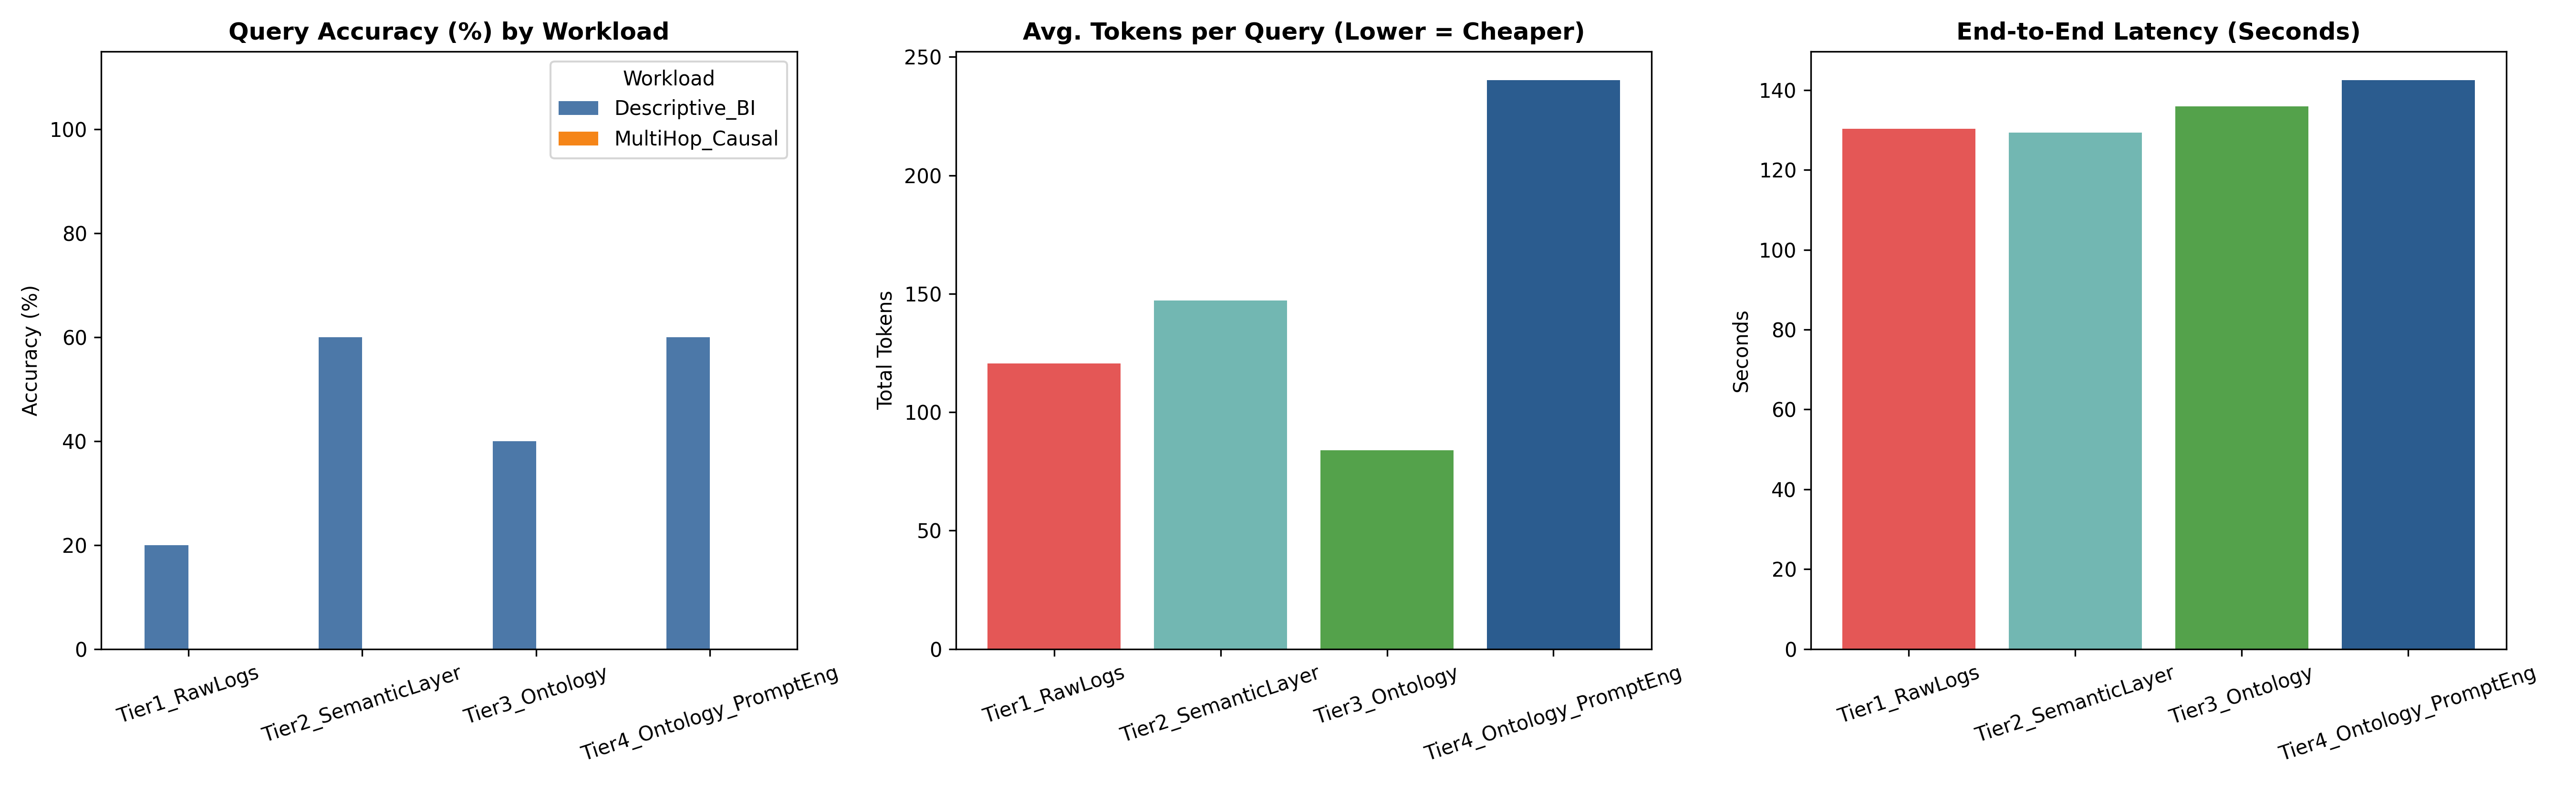

In [9]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5), dpi=300)

# Panel 1: Accuracy (%) by Workload Type
piv_acc = summary_df.pivot(index="tier", columns="workload_type", values="accuracy_pct")
piv_acc.plot(kind="bar", ax=axes[0], color=["#4C78A8", "#F58518"], rot=18)
axes[0].set_title("Query Accuracy (%) by Workload", fontweight="bold")
axes[0].set_ylabel("Accuracy (%)")
axes[0].set_xlabel("")
axes[0].set_ylim(0, 115)
axes[0].legend(title="Workload")

# Panel 2: Average Token Consumption per Query
tier_totals = df_results.groupby("tier", as_index=False).agg(
    avg_tokens=("total_tokens", "mean"),
    avg_latency=("latency_sec", "mean"),
)
colors = ["#E45756", "#72B7B2", "#54A24B", "#2B5C8F"]
axes[1].bar(tier_totals["tier"], tier_totals["avg_tokens"], color=colors)
axes[1].set_title("Avg. Tokens per Query (Lower = Cheaper)", fontweight="bold")
axes[1].set_ylabel("Total Tokens")
axes[1].tick_params(axis="x", rotation=18)

# Panel 3: End-to-End Latency (Seconds)
axes[2].bar(tier_totals["tier"], tier_totals["avg_latency"], color=colors)
axes[2].set_title("End-to-End Latency (Seconds)", fontweight="bold")
axes[2].set_ylabel("Seconds")
axes[2].tick_params(axis="x", rotation=18)

plt.tight_layout()
plt.show()
